# Dipole sources

This notebook shows how to use a point dipole source in FDTDX. We place one electric dipole in the center of an
empty box, surround the box with absorbing boundaries, run the simulation and watch the wave spread out.

Sections 1 and 2 cover the physics of a radiating dipole. Section 3 explains how FDTDX implements it, and
Section 4 explains why the box needs absorbing boundaries on every side. The simulation itself is set up in
Sections 5 to 7.

## 1. The dipole as a source

The simplest radiating object is a pair of opposite charges $+q$ and $-q$ whose separation $\mathbf d(t)$
oscillates. Its dipole moment is

$$ \mathbf{p}(t) = q\, \mathbf{d}(t). $$

Whenever $\mathbf p$ changes in time, the dipole radiates. The same thing can be described as a short piece of wire
of length $\ell$ that carries a current $I(t) = I_0\cos(\omega t)$, which gives $\dot p = I\ell$. If $\ell$ is much
smaller than the wavelength, this is called a Hertzian dipole.

A point dipole is worth knowing for two reasons. First, small emitters such as atoms, molecules and quantum dots
radiate mostly like oscillating electric dipoles. In nanophotonics a point dipole is therefore the usual way to
model spontaneous emission, for example to compute the Purcell factor of a cavity. Second, the field of a point
source is the Green's function of Maxwell's equations: the field of any current distribution is a sum of
dipole fields with the right amplitudes and phases.

A dipole also differs from a plane wave in that it radiates in all directions at once. This is why the box in this
notebook needs absorbing boundaries on all six faces.

## 2. The radiated field

(The FDTDX notebooks on [Maxwell's Equations](https://fdtdx.readthedocs.io/en/latest/notebooks/physics/01_maxwell.html)
and the [FDTD Method](https://fdtdx.readthedocs.io/en/latest/notebooks/physics/02_fdtd.html) cover the underlying
equations and the Yee grid. Here we only look at what is specific to dipoles.)

In Maxwell's equations a dipole appears as a free current density $\mathbf J$ in the Ampère–Maxwell law,

$$ \nabla \times \mathbf H = \mathbf J + \frac{\partial \mathbf D}{\partial t}. $$

For a point dipole at the origin that oscillates along $\hat{\mathbf p}$ with angular frequency $\omega$, the current
density is

$$ \mathbf J(\mathbf r, t) = \hat{\mathbf p}\, I_0 \cos(\omega t)\, \delta^3(\mathbf r). $$

The resulting field has terms that fall off as $1/r$, $1/r^2$ and $1/r^3$ with the distance $r$ from the dipole:

- Close to the dipole ($r \ll \lambda$) the $1/r^2$ and $1/r^3$ terms dominate. This is the near field. It stores
  energy but does not carry it away.
- Far from the dipole ($r \gg \lambda$) only the $1/r$ term is left. This is the radiation field. The power it
  carries through a sphere of radius $r$ is proportional to $|\mathbf E|^2 r^2$, which does not depend on $r$, so
  the energy keeps flowing outward.
- The crossover between the two is at roughly $r \approx \lambda / 2\pi$.

The far field is not the same in all directions. The radiated power per solid angle is

$$ P(\theta) \propto \sin^2\theta, $$

where $\theta$ is the angle to the dipole axis. There is no radiation along the axis and the most radiation
perpendicular to it, so the pattern looks like a doughnut around the dipole. We will look for this in the
simulation.

## 3. How FDTDX injects a dipole

FDTD advances $\mathbf E$ and $\mathbf H$ on a staggered Yee grid, one time step at a time. To add a dipole, the
current term $\mathbf J$ from the Ampère–Maxwell law is added to the update equation in a single cell at every time
step. For the electric dipole `fdtdx.PointDipoleSource` does this:

$$ E_i[x,y,z] \;\mathrel{+}=\; -c\,\big(\varepsilon^{-1} \hat{\mathbf p}\big)_i \cdot \text{amplitude} \cdot
\text{temporal}(t) $$

The source is *soft*: it adds to the field that is already in the cell instead of overwriting it. A hard source
would act like a small metal point at the dipole position and reflect any wave that comes back to it. With a soft
source, scattered or reflected light passes through the dipole cell undisturbed.

The main parameters are:

- `polarization` is the axis of the dipole (0 for x, 1 for y, 2 for z). `azimuth_angle` and `elevation_angle`
  tilt it away from that axis.
- `source_type` is `"electric"` or `"magnetic"`. A magnetic dipole is injected into the $\mathbf H$ update instead.
- `amplitude` scales the source.
- `wave_character` sets the frequency, given as a wavelength, a frequency or a period.
- `temporal_profile` is the time dependence. The default is `SingleFrequencyProfile`, a sine wave whose amplitude
  is ramped up linearly over the first four periods. The ramp avoids a sudden switch-on, which would add broadband
  noise.

One more thing to watch: if you do not give a source a size, FDTDX stretches it over the whole simulation volume.
For a point dipole you have to ask for a single cell with `partial_grid_shape=(1, 1, 1)`. Without it, the current is
injected in every cell of the box at the same time, and instead of a spreading wave you get a uniform field that
just oscillates in time.

## 4. Absorbing boundaries on all sides

An FDTD box is finite, but a dipole in free space radiates into an infinite domain. If the grid simply ended at a
wall, the outgoing wave would be reflected there and travel back into the box.

The usual solution is a Perfectly Matched Layer (PML): a lossy layer around the box that is matched to the interior
so that waves enter it with almost no reflection and are damped as they travel through it. The wave that reaches
the outer edge is negligibly small.

For a plane wave, PML is often needed only on the side the wave travels towards, and the other sides can be
periodic. A dipole radiates in every direction, so here all six faces get a PML:

```python
bound_cfg = fdtdx.BoundaryConfig.from_uniform_bound(thickness=10, boundary_type="pml")
```

`from_uniform_bound` applies the same settings to the $\pm x$, $\pm y$ and $\pm z$ faces. The thickness is given in
grid cells.

## 5. Setting up the simulation

The scene is an empty cubic box of vacuum with PML on all six faces and one electric dipole at its center.
We start with the imports.

In [1]:
import time

import fdtdx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pytreeclass as tc
from IPython.display import Video

%matplotlib inline

### 5.1 Simulation configuration

We use a wavelength of 1550 nm. The physics does not depend on this choice as long as the grid resolves the
wavelength. We use 16 grid cells per wavelength, which is within the usual range of 10 to 20.

In [6]:
# FDTDX needs a random key even for a deterministic simulation like this one
key = jax.random.PRNGKey(42)

WAVELENGTH = 1.55e-6          # 1550 nm
SPEED_OF_LIGHT = 299_792_458.0

config = fdtdx.SimulationConfig(
    time=60e-15,                    # total simulated time
    grid=fdtdx.UniformGrid(spacing=WAVELENGTH / 16),     # ~16 grid cells per wavelength
    dtype=jnp.float32,
    courant_factor=0.99,
)

### 5.2 Simulation volume and boundaries

`object_list` holds all objects in the scene and `constraints` holds the rules FDTDX uses to find their positions
and sizes on the grid (see the
[Object Placement Guide](https://fdtdx.readthedocs.io/en/latest/notebooks/quickstart/03_object_placement_guide.html)).
The simulation volume is also the background material, which here is vacuum ($\varepsilon_r = \mu_r = 1$).

In [9]:
object_list = []
constraints = []

VOLUME_SIZE = 10e-6   # 10 micron cube, about 6.5 wavelengths across

volume = fdtdx.SimulationVolume(
    partial_real_shape=(VOLUME_SIZE, VOLUME_SIZE, VOLUME_SIZE),
    material=fdtdx.Material(permittivity=1.0, permeability=1.0),   # vacuum background
)
object_list.append(volume)

In [11]:
# PML absorbing boundaries on all six faces (+x, -x, +y, -y, +z, -z)
bound_cfg = fdtdx.BoundaryConfig.from_uniform_bound(thickness=10, boundary_type="pml")
bound_dict, bound_constraints = fdtdx.boundary_objects_from_config(bound_cfg, volume)

object_list.extend(bound_dict.values())
constraints.extend(bound_constraints)


### 5.3 The dipole

The dipole points along $z$ (`polarization=2`) and oscillates at our chosen wavelength. As explained in Section 3,
`partial_grid_shape=(1, 1, 1)` makes it a single cell. `place_at_center(volume)` puts that cell in the middle of
the box.

In [14]:
dipole = fdtdx.PointDipoleSource(
    name="Dipole",
    wave_character=fdtdx.WaveCharacter(wavelength=WAVELENGTH),
    polarization=2,          # 0=x, 1=y, 2=z -> the dipole oscillates along z
    source_type="electric",
    amplitude=1.0,
    partial_grid_shape=(1, 1, 1),   # a single Yee cell; without this the source fills the whole volume
)
object_list.append(dipole)
constraints.append(dipole.place_at_center(volume))

### 5.4 Detector

To see the field we need a detector. The `EnergyDetector` records the energy density, which is proportional to
$\varepsilon |\mathbf E|^2 + \mu |\mathbf H|^2$, on the three cut planes through the center of the box (`as_slices=True`
stores only these planes, not the full 3D volume).

In [17]:
# Energy density on the three cut planes through the center, recorded every 2 time steps
energy_detector = fdtdx.EnergyDetector(
    name="EnergyVideo",
    as_slices=True,
    switch=fdtdx.OnOffSwitch(interval=2),
    exact_interpolation=True,
)
object_list.append(energy_detector)
constraints.extend(energy_detector.same_position_and_size(volume))

### 5.5 Placing the objects

`fdtdx.place_objects` resolves all constraints into concrete grid positions and sizes. `fdtdx.plot_setup` draws the
result, so we can check that the dipole is a single cell in the center and that the PML surrounds the box before
we run anything.

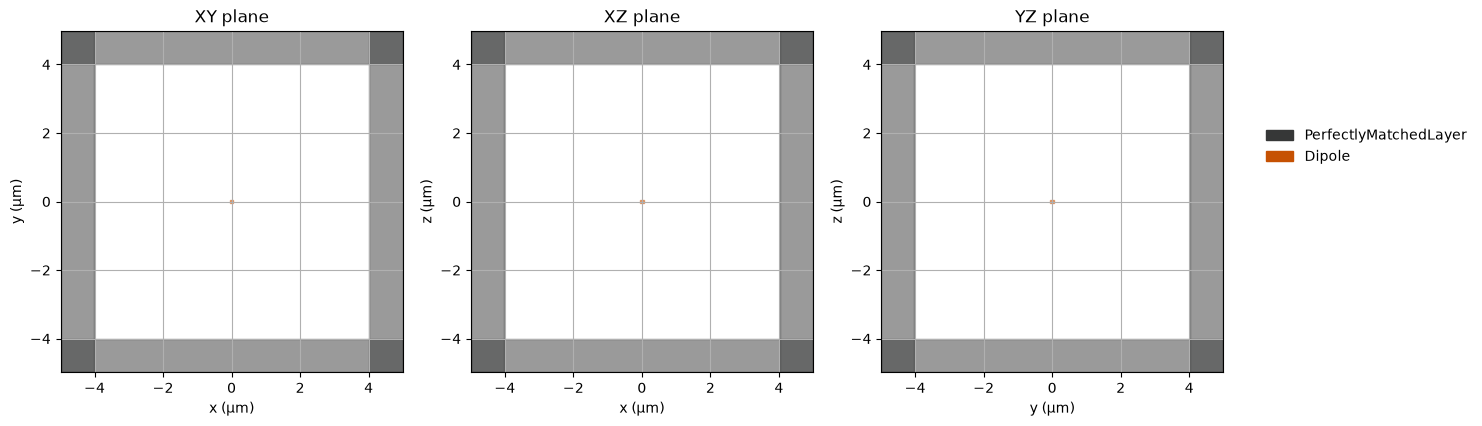

┌───────────────────────────┬──────────────────┬──────────┬───────┐
│Name                       │Type              │Count     │Size   │
├───────────────────────────┼──────────────────┼──────────┼───────┤
│.fields                    │FieldState        │9,102,522 │34.72MB│
├───────────────────────────┼──────────────────┼──────────┼───────┤
│.inv_permittivities        │f32[1,103,103,103]│1,092,727 │4.17MB │
├───────────────────────────┼──────────────────┼──────────┼───────┤
│.inv_permeabilities        │float             │1         │       │
├───────────────────────────┼──────────────────┼──────────┼───────┤
│.detector_states           │dict              │5,187,801 │19.79MB│
├───────────────────────────┼──────────────────┼──────────┼───────┤
│.recording_state           │NoneType          │          │       │
├───────────────────────────┼──────────────────┼──────────┼───────┤
│.electric_conductivity     │NoneType          │          │       │
├───────────────────────────┼──────────────────┼

In [20]:
key, subkey = jax.random.split(key)
objects, arrays, params, config, _ = fdtdx.place_objects(
    object_list=object_list,
    config=config,
    constraints=constraints,
    key=subkey,
)

fig = fdtdx.plot_setup(
    config=config,
    objects=objects,
    exclude_object_list=[energy_detector],
)
plt.show()

# Where the memory goes
print(tc.tree_summary(arrays, depth=1))

## 6. Running the simulation

`fdtdx.apply_params` prepares the objects and `fdtdx.run_fdtd` runs the time-stepping loop. We put both in one
function so that JAX can compile it.

In [23]:
def sim_fn(params, arrays, key):
    arrays, new_objects, _ = fdtdx.apply_params(arrays, objects, params, key)
    final_state = fdtdx.run_fdtd(
        arrays=arrays,
        objects=new_objects,
        config=config,
        key=key,
    )
    _, arrays = final_state
    return arrays


In [25]:
start_time = time.time()
jitted_sim_fn = jax.jit(sim_fn).lower(params, arrays, key).compile()
print(f"Compilation time: {time.time() - start_time:.2f} s")


Compilation time: 0.43 s


In [27]:
start_time = time.time()
new_arrays = jitted_sim_fn(params, arrays, subkey)
print(f"Simulation runtime: {time.time() - start_time:.2f} s")


FDTD (checkpointed):   0%|                            | 0/325 [00:00<?, ?step/s]

Simulation runtime: 1.58 s


## 7. Watching the dipole radiate

The energy density near the dipole is many orders of magnitude larger than in the radiated wave. In the near field
it falls off like $1/r^6$. On a linear color scale the video would show only a bright dot at the center and nothing
else. We therefore plot the logarithm of the energy density, relative to its maximum, over six decades. The side
effect is that very small values are exaggerated, so faint artifacts such as weak reflections from the PML also
become visible.

The video shows two planes through the dipole. The left one is the XZ plane, which contains the dipole axis. The
right one is the XY plane, perpendicular to the axis. Things to look for:

1. A front expands from the center at roughly the speed of light. It is a circle in the XY plane and reaches the
   PML after about 20 fs. Because the source ramps up from zero, the first part of the wave is very weak and falls
   below the color scale, so the visible front sits a little behind the true wave front.
2. Behind the front the energy forms rings that keep moving outward. The energy density oscillates at twice the
   optical frequency, so the rings are spaced by half a wavelength, about 0.8 µm.
3. In the XZ plane the energy to the sides of the dipole is several times larger than above and below it. This
   is the $\sin^2\theta$ pattern from Section 2. In the XY plane it is the same in all directions.
4. At the edges there is a thin dark band where the PML absorbs the wave.

In [30]:
import imageio_ffmpeg
import matplotlib.animation as animation
import numpy as np
import tempfile

plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()


def make_energy_video(state, interval, decades=6, fps=15):
    # Video of log10(energy density / max) in the XZ and XY planes through the dipole
    xz = np.asarray(state["XZ Plane"])   # axes: (time, x, z)
    xy = np.asarray(state["XY Plane"])   # axes: (time, x, y)
    peak = max(xz.max(), xy.max())
    to_log = lambda a: np.log10(np.maximum(a / peak, 10.0 ** -decades))

    half = xz.shape[1] * (WAVELENGTH / 16) / 2 * 1e6   # half box size in um
    extent = [-half, half, -half, half]
    dt = config.time_step_duration

    fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=100, constrained_layout=True)
    kwargs = dict(cmap="inferno", vmin=-decades, vmax=0, origin="lower", extent=extent)
    im_xz = axes[0].imshow(to_log(xz[0]).T, **kwargs)
    im_xy = axes[1].imshow(to_log(xy[0]).T, **kwargs)
    axes[0].set_xlabel("x (µm)")
    axes[0].set_ylabel("z (µm)")
    axes[0].set_title("XZ plane (contains the dipole axis)")
    axes[1].set_xlabel("x (µm)")
    axes[1].set_ylabel("y (µm)")
    axes[1].set_title("XY plane")
    fig.colorbar(im_xy, ax=axes, shrink=0.8, label="log10(energy density / maximum)")
    label = fig.suptitle("")

    path = tempfile.mkstemp(suffix=".mp4")[1]
    writer = animation.FFMpegWriter(fps=fps)
    with writer.saving(fig, path, dpi=100):
        for i in range(xz.shape[0]):
            im_xz.set_data(to_log(xz[i]).T)
            im_xy.set_data(to_log(xy[i]).T)
            label.set_text(f"t = {i * interval * dt * 1e15:.1f} fs")
            writer.grab_frame()
    plt.close(fig)
    return path


video_path = make_energy_video(new_arrays.detector_states["EnergyVideo"], interval=2)
Video(video_path, embed=True, width=720)